In [30]:
# Importing the libraries
import pandas as pd   # For data loading and cleaning
from sklearn.model_selection import train_test_split  # 80% for training and 20% for testing
from sklearn.linear_model import LogisticRegression  # model used for fitting variable and predictions are made on independent variables
from sklearn.metrics import accuracy_score  # for model evaluation
import matplotlib.pyplot as plt  # for data visuliasation
import plotly.express as px   # for advance visualisation
import seaborn as sns   # for correlation matrix (heatmap)

In [3]:
# Data Collection
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv("Social_Network_Ads.csv")

Saving Social_Network_Ads.csv to Social_Network_Ads (1).csv


In [4]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [5]:
# EDA
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [6]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [7]:
df.isnull().sum()

,0
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [8]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [11]:
df.tail(3)

,User ID,Gender,Age,EstimatedSalary,Purchased
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0
399,15594041,Female,49,36000,1


In [12]:
# Dropping the unwanted columns
df = df.drop(columns = ['User ID'])

In [13]:
df

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0
...,...,...,...,...
395,Female,46,41000,1
396,Male,51,23000,1
397,Female,50,20000,1
398,Male,36,33000,0


In [15]:
# LableEncoder will convert text values into numeric values
from sklearn.preprocessing import LabelEncoder

In [16]:
le = LabelEncoder()

In [18]:
df.columns

Index(['Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [21]:
df['Gender'] = le.fit_transform(df['Gender'])

In [22]:
df

,Gender,Age,EstimatedSalary,Purchased
0,1,19,19000,0
1,1,35,20000,0
2,0,26,43000,0
3,0,27,57000,0
4,1,19,76000,0
...,...,...,...,...
395,0,46,41000,1
396,1,51,23000,1
397,0,50,20000,1
398,1,36,33000,0


In [23]:
corr = df.corr()

In [24]:
corr

,Gender,Age,EstimatedSalary,Purchased
Gender,1.000000,-0.073741,-0.060435,-0.042469
Age,-0.073741,1.000000,0.155238,0.622454
EstimatedSalary,-0.060435,0.155238,1.000000,0.362083
Purchased,-0.042469,0.622454,0.362083,1.000000


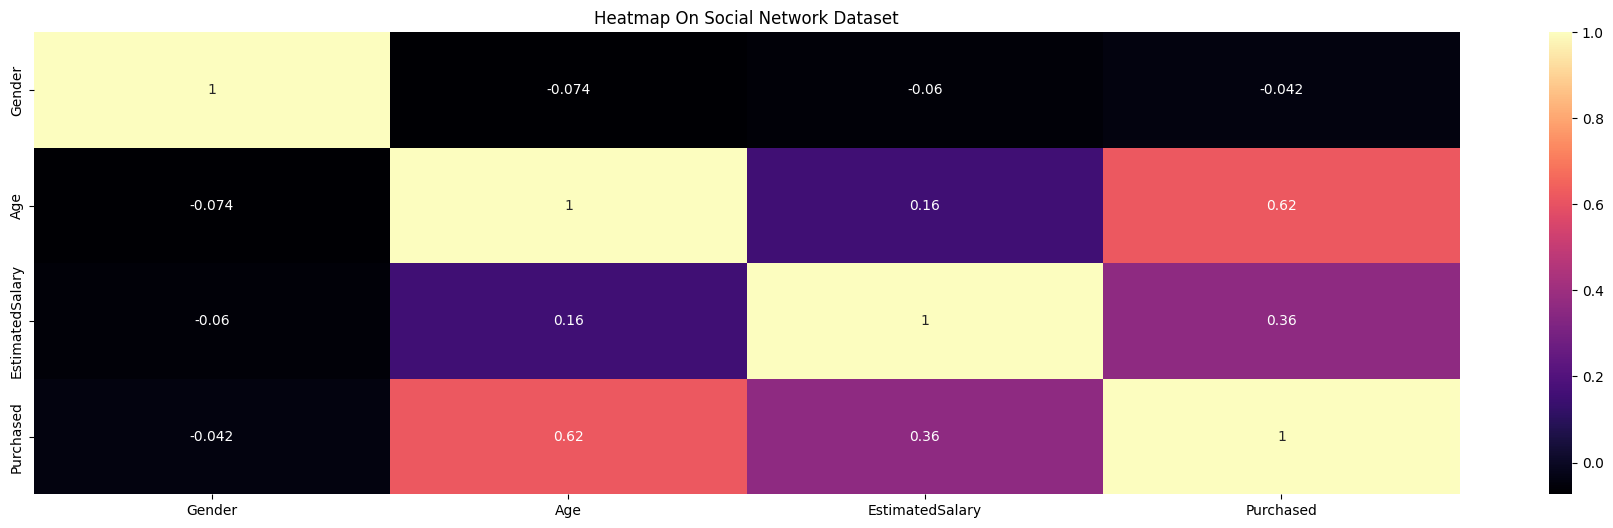

In [25]:
plt.figure(figsize = (23,6))
sns.heatmap(corr , annot = True , cmap = 'magma')
plt.title("Heatmap On Social Network Dataset")
plt.show()

In [26]:
# Dividing Data Into X and y
df.columns

Index(['Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [34]:
X = df.drop(columns = ['Purchased'])
y = df['Purchased']

In [28]:
X

,Gender,Age,EstimatedSalary
0,1,19,19000
1,1,35,20000
2,0,26,43000
3,0,27,57000
4,1,19,76000
...,...,...,...
395,0,46,41000
396,1,51,23000
397,0,50,20000
398,1,36,33000


In [35]:
y

,Purchased
0,0
1,0
2,0
3,0
4,0
...,...
395,1
396,1
397,1
398,0


In [36]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2 , random_state = 42)

In [37]:
X_train

,Gender,Age,EstimatedSalary
3,0,27,57000
18,1,46,28000
202,0,39,134000
250,0,44,39000
274,0,57,26000
...,...,...,...
71,0,24,27000
106,0,26,35000
270,0,43,133000
348,1,39,77000


In [38]:
y_train

,Purchased
3,0
18,1
202,1
250,0
274,1
...,...
71,0
106,0
270,0
348,0


In [39]:
X_test

,Gender,Age,EstimatedSalary
209,0,46,22000
280,0,59,88000
33,0,28,44000
210,0,48,96000
93,0,29,28000
...,...,...,...
246,0,35,50000
227,1,56,133000
369,0,54,26000
176,0,35,47000


In [40]:
y_test

,Purchased
209,0
280,1
33,0
210,1
93,0
...,...
246,0
227,1
369,1
176,0


In [41]:
# Model Calling for fitting training variables
model = LogisticRegression()

In [42]:
model.fit(X_train,y_train)

LogisticRegression()

In [44]:
y_pred = model.predict(X_test)

In [45]:
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [46]:
y_test

,Purchased
209,0
280,1
33,0
210,1
93,0
...,...
246,0
227,1
369,1
176,0


In [47]:
acc = accuracy_score(y_test , y_pred)

In [48]:
acc

0.8875

In [49]:
print("Accuracy Score : ", acc*100, '%')

Accuracy Score :  88.75 %


In [51]:
m1 = model.score(X_train,y_train)
m2 = model.score(X_test,y_test)

In [52]:
print("Training Score : " , m1*100 , '%')
print("Testing Score : " , m2*100 , '%')

Training Score :  83.4375 %
Testing Score :  88.75 %


In [53]:
model.intercept_

array([-11.69199787])

In [54]:
model.coef_

array([[2.84619221e-01, 2.10719873e-01, 3.58422448e-05]])